# Challenge 1

Task:

The objective is to detect and segment individual screws and nuts in each input image, producing a labelled image in which each detected part has a unique integer ID. The total number of detected parts must also be reported.

At least three segmentation methodologies from different algorithm families will be investigated and compared to determine which is most suitable for this dataset.

Approach:

Different segmentation methods will be developed and evaluated on the same test images.

To ensure a fair comparison, the same post-processing procedure will be applied to each method so that differences in performance can be attributed primarily to the segmentation approach.

The methods will be evaluated using the available annotated images, with particular attention to separating metal parts from the wooden background.

Evaluation:

The best-performing segmentation method will be selected based on the evaluation results and its suitability for producing individual labelled components.


## Environmental Setup
In this section the following tasks are performed:
- Initialization of the reference environment
- Configuration of relative directory paths
- Using of a set of images to do the exploration part, in order to avoid overfitting

In [1]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from skimage.filters import threshold_local
from skimage.morphology import remove_small_objects, remove_small_holes, opening, disk
from scipy.ndimage import binary_fill_holes

# Define project directories
INPUT_DIR = Path("inputs")
ANNOTATIONS_DIR = Path("annotations")
VALID_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Filter only supported image extensions
image_paths = sorted([p for p in INPUT_DIR.iterdir() if p.suffix.lower() in VALID_EXTS])
labelled_image_paths = sorted([p for p in ANNOTATIONS_DIR.iterdir() if p.suffix.lower() in VALID_EXTS])

print(f"Total images found: {len(image_paths)}")
if not image_paths:
    raise FileNotFoundError(f"No valid image files found in '{INPUT_DIR.resolve()}'.")

Total images found: 384


In [2]:
DEV_MODE = True       # Set to False when running tests

if DEV_MODE:

    # Pick a spread of images that covers diferent setups
    #hard_stems = {"009","011","018","112","209","377","257","302","199","154"}
    dev_stems = {"026","027","028","029","040","041","042","061","063","119"}
    active_paths = [p for p in image_paths if any(p.stem.endswith(s) for s in dev_stems)]

    print(f"Running in DEV MODE on {len(active_paths)} images.")
else:
    active_paths = image_paths
    print(f"Running in FULL MODE on all {len(active_paths)} images.")

Running in DEV MODE on 10 images.


## Exploratory Analysis & Color Space Justification

**Core questions addressed:**
- Which colour channels maximise the contrast between parts and the wooden substrate?
- Why do global thresholding approaches fail on this dataset?

First analyse RGB, HSV, and LAB colour channels

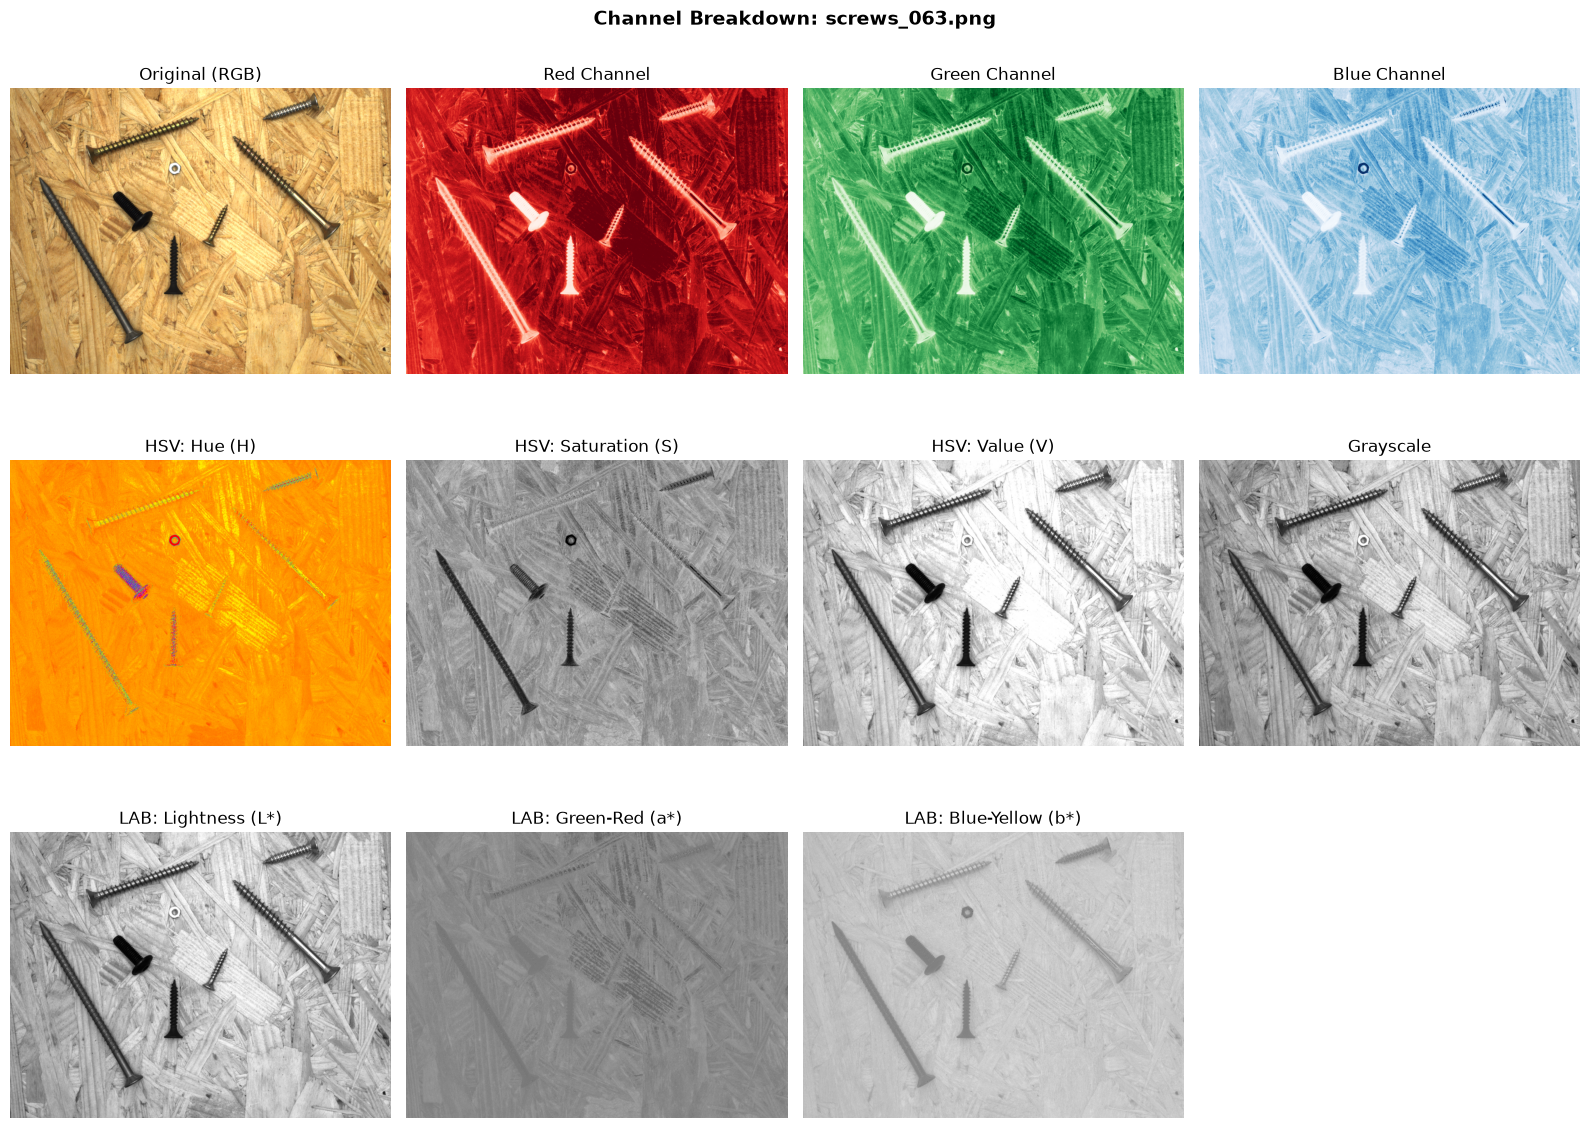

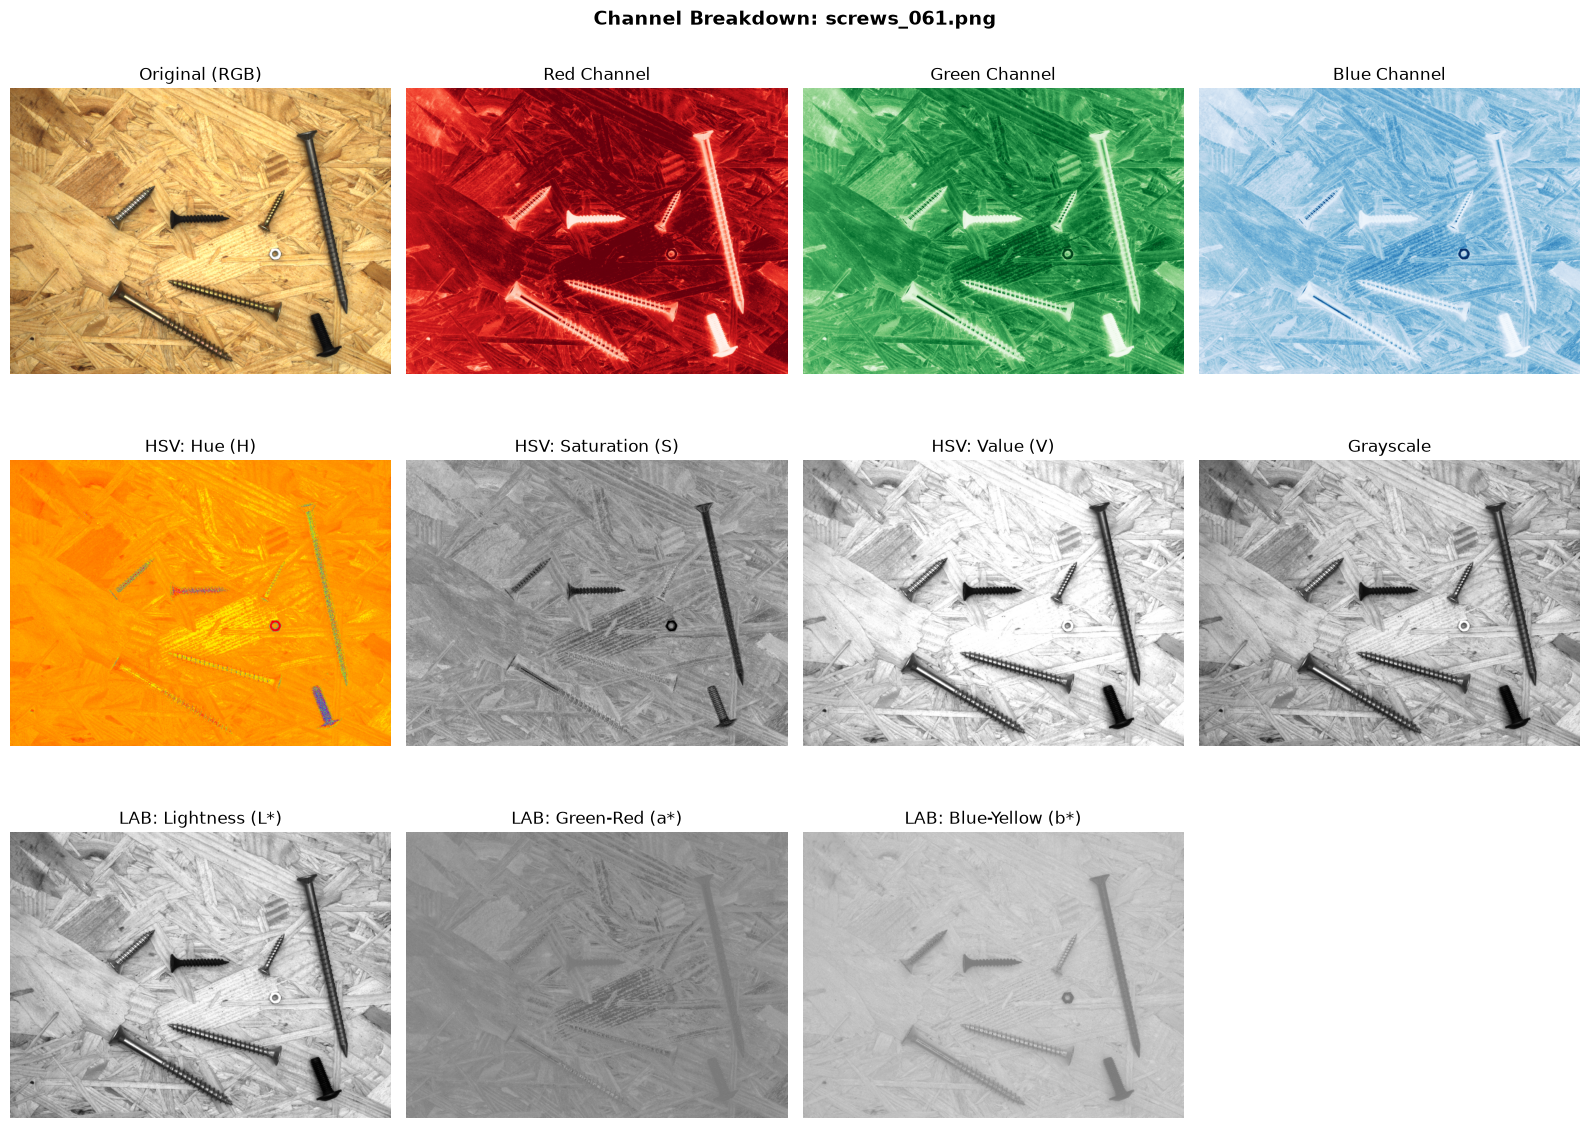

In [7]:
def inspect_image_channels(img_path: Path):
    # cv2.imread loads in BGR
    bgr = cv2.imread(str(img_path))
    if bgr is None:
        print(f"Error loading {img_path}")
        return

    # Color space conversions
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

    # Increased figure height and added a 3rd row
    fig, axes = plt.subplots(3, 4, figsize=(16, 12))
    fig.suptitle(f"Channel Breakdown: {img_path.name}", fontsize=14, weight="bold")

    # Row 1: RGB components
    axes[0, 0].imshow(rgb)
    axes[0, 0].set_title("Original (RGB)")
    axes[0, 1].imshow(rgb[:, :, 0], cmap="Reds")
    axes[0, 1].set_title("Red Channel")
    axes[0, 2].imshow(rgb[:, :, 1], cmap="Greens")
    axes[0, 2].set_title("Green Channel")
    axes[0, 3].imshow(rgb[:, :, 2], cmap="Blues")
    axes[0, 3].set_title("Blue Channel")

    # Row 2: HSV & Grayscale components
    axes[1, 0].imshow(hsv[:, :, 0], cmap="hsv")
    axes[1, 0].set_title("HSV: Hue (H)")
    axes[1, 1].imshow(hsv[:, :, 1], cmap="gray")
    axes[1, 1].set_title("HSV: Saturation (S)")
    axes[1, 2].imshow(hsv[:, :, 2], cmap="gray")
    axes[1, 2].set_title("HSV: Value (V)")
    axes[1, 3].imshow(gray, cmap="gray")
    axes[1, 3].set_title("Grayscale")

    # Row 3: LAB components
    axes[2, 0].imshow(lab[:, :, 0], cmap="gray")
    axes[2, 0].set_title("LAB: Lightness (L*)")
    axes[2, 1].imshow(lab[:, :, 1], cmap="gray")
    axes[2, 1].set_title("LAB: Green-Red (a*)")
    axes[2, 2].imshow(lab[:, :, 2], cmap="gray")
    axes[2, 2].set_title("LAB: Blue-Yellow (b*)")
    
    # Disable the unused 4th subplot in the bottom row
    axes[2, 3].set_visible(False)

    for ax in axes.ravel():
        ax.axis("off")

    plt.tight_layout()
    plt.show()

# 2nd last and 3rd last images in DEV set have golden screws
for path in active_paths[-2:-4:-1]: 
    inspect_image_channels(path)

While some channels isolate the golden screws, they often fail to remove the noise from the chipped wood background. The LAB b* (Blue-Yellow) channel is the most effective because it mutes the background texture while maintaining a clear, solid silhouette of the golden screws. Although the Red and Green channels highlight the edges of the fasteners, they fail to separate the main body of the screw from the wood grain. Therefore, the b* channel provides the cleanest overall separation.

By analyzing `screws_063.png`, which contains two golden screws identified via ground-truth annotations (ID=6 and ID=8), the histogram of the LAB b* channel can be directly compared against other promising colour planes (e.g., RGB Red, HSV Hue, and HSV Value).

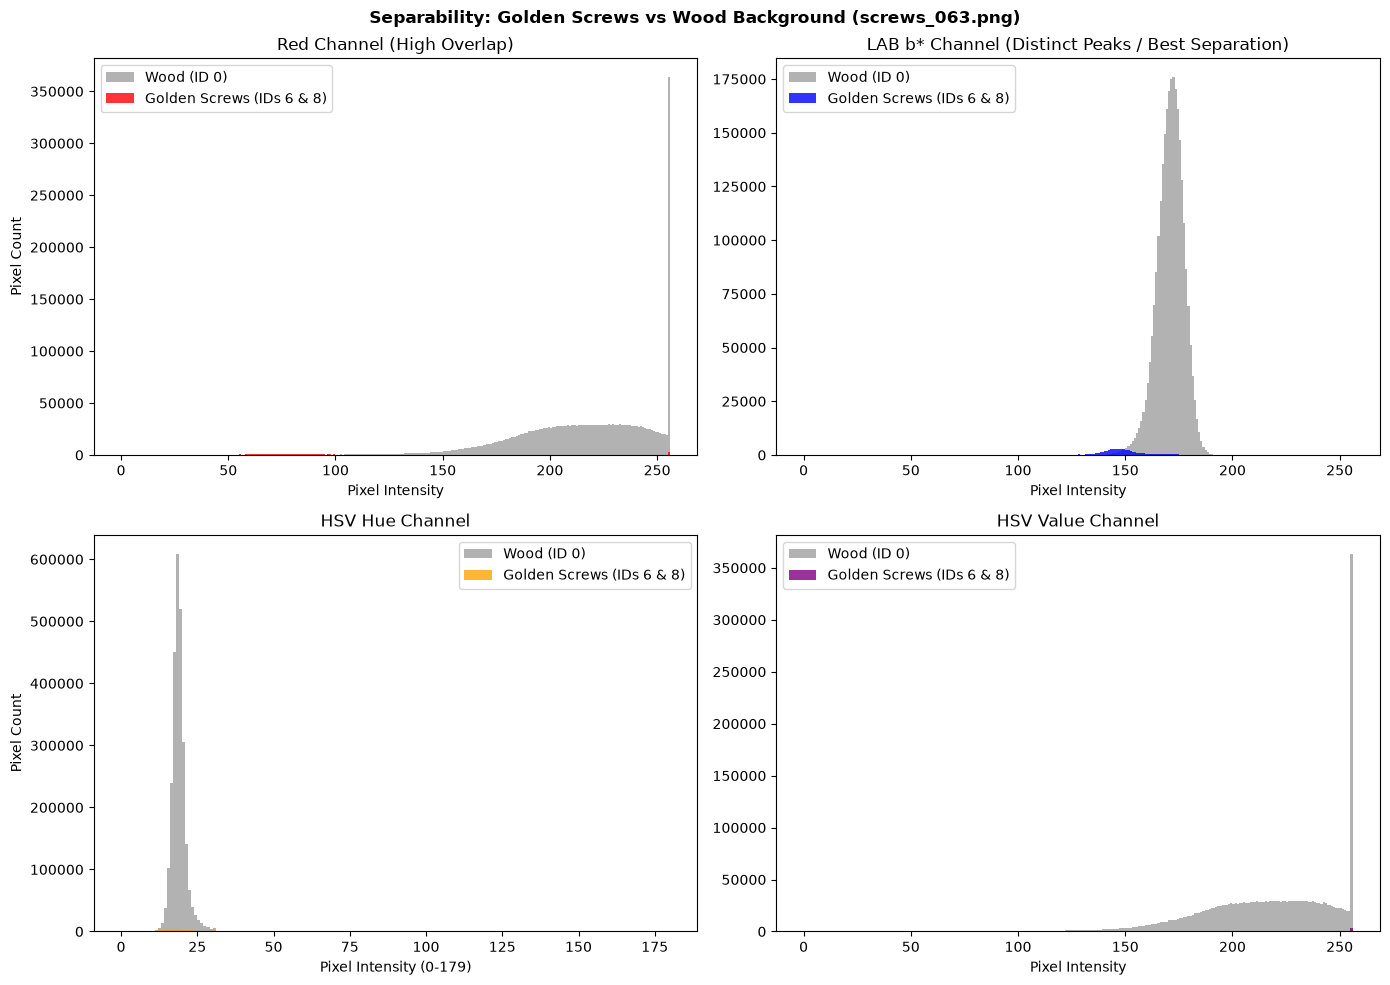

In [15]:
# Safely locate image 063
target_path = next((p for p in active_paths if "063" in p.stem), None)

if not target_path:
    print("Error: Image containing '063' not found in active paths.")
else:
    mask_path = Path("annotations") / f"{target_path.stem}_labels{target_path.suffix}"

    bgr = cv2.imread(str(target_path))
    mask = cv2.imread(str(mask_path), cv2.IMREAD_UNCHANGED)

    # Gracefully handle missing files
    if bgr is None or mask is None:
        print(f"Error: Failed to load image or mask for {target_path.name}. Check your directories.")
    else:
        # Extract the four channels
        red_channel = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)[:, :, 0]
        b_channel = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)[:, :, 2]
        hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
        hue_channel = hsv[:, :, 0]
        value_channel = hsv[:, :, 2]

        # Explicitly isolate the background (0) and golden screws (6, 8)
        bg_mask = (mask == 0)
        gold_mask = (mask == 6) | (mask == 8)

        # Create a 2x2 grid for the 4 histograms
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        fig.suptitle(f"Separability: Golden Screws vs Wood Background ({target_path.name})", weight="bold")

        # 1. Red Channel Histogram
        axes[0, 0].hist(red_channel[bg_mask], bins=256, range=(0, 256), color='gray', alpha=0.6, label='Wood (ID 0)')
        axes[0, 0].hist(red_channel[gold_mask], bins=256, range=(0, 256), color='red', alpha=0.8, label='Golden Screws (IDs 6 & 8)')
        axes[0, 0].set_title("Red Channel (High Overlap)")
        axes[0, 0].set_xlabel("Pixel Intensity")
        axes[0, 0].set_ylabel("Pixel Count")
        axes[0, 0].legend()

        # 2. b* Channel Histogram
        axes[0, 1].hist(b_channel[bg_mask], bins=256, range=(0, 256), color='gray', alpha=0.6, label='Wood (ID 0)')
        axes[0, 1].hist(b_channel[gold_mask], bins=256, range=(0, 256), color='blue', alpha=0.8, label='Golden Screws (IDs 6 & 8)')
        axes[0, 1].set_title("LAB b* Channel (Distinct Peaks / Best Separation)")
        axes[0, 1].set_xlabel("Pixel Intensity")
        axes[0, 1].legend()

        # 3. Hue Channel Histogram (OpenCV scales Hue 0-179)
        axes[1, 0].hist(hue_channel[bg_mask], bins=180, range=(0, 180), color='gray', alpha=0.6, label='Wood (ID 0)')
        axes[1, 0].hist(hue_channel[gold_mask], bins=180, range=(0, 180), color='orange', alpha=0.8, label='Golden Screws (IDs 6 & 8)')
        axes[1, 0].set_title("HSV Hue Channel")
        axes[1, 0].set_xlabel("Pixel Intensity (0-179)")
        axes[1, 0].set_ylabel("Pixel Count")
        axes[1, 0].legend()

        # 4. Value Channel Histogram
        axes[1, 1].hist(value_channel[bg_mask], bins=256, range=(0, 256), color='gray', alpha=0.6, label='Wood (ID 0)')
        axes[1, 1].hist(value_channel[gold_mask], bins=256, range=(0, 256), color='purple', alpha=0.8, label='Golden Screws (IDs 6 & 8)')
        axes[1, 1].set_title("HSV Value Channel")
        axes[1, 1].set_xlabel("Pixel Intensity")
        axes[1, 1].legend()

        plt.tight_layout()
        plt.show()

Based on the generated histograms, the LAB b* channel provides the best separation between the two materials. In the Red, Hue and Value channels, the pixel distributions for the wood background and the golden screws completely overlap, making it impossible to isolate the screws using a simple threshold. In contrast, the LAB b* channel histogram displays two distinct, semi-separated peaks. Some of the golden screws cluster cleanly around a lower pixel intensity, while the wood background forms a massive separate peak at a higher intensity.

## 1. Global Thresholding

Since the Lab b* channel was found to provide useful separation between metal parts and the wooden background, the first segmentation method considered is global thresholding.

Otsu's algorithm is used to automatically select a threshold by maximising the between-class variance of the pixel intensity distribution. A single threshold is then applied across the entire image.

Before thresholding, a small Gaussian blur (5×5) is applied to reduce high-frequency noise and local variations caused by the textured wooden background. However, this may also remove fine details from very narrow screws.

In [16]:
def segment_global_threshold(image):

    # Convert image from BGR to Lab
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)

    # Extract b* channel
    b_channel = lab[:, :, 2]

    # Reduce small variations and noise
    blurred = cv2.GaussianBlur(b_channel, (5, 5), 0)

    # Global Otsu threshold
    threshold, mask = cv2.threshold(
        blurred,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    return mask

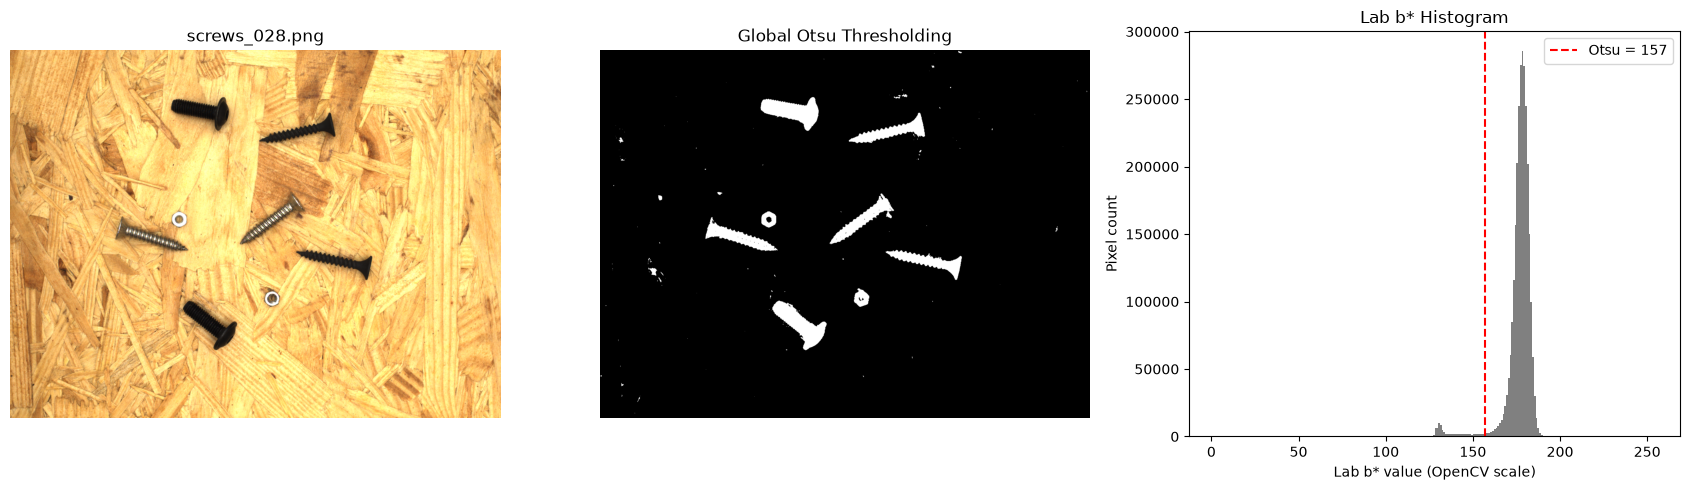

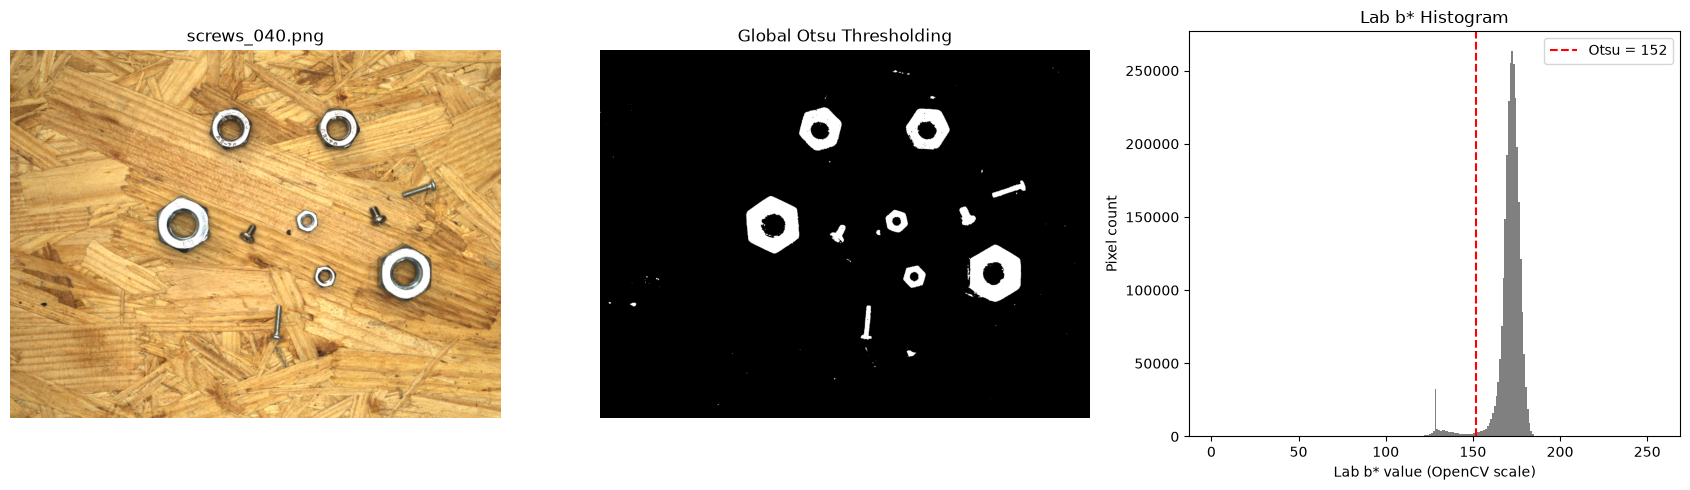

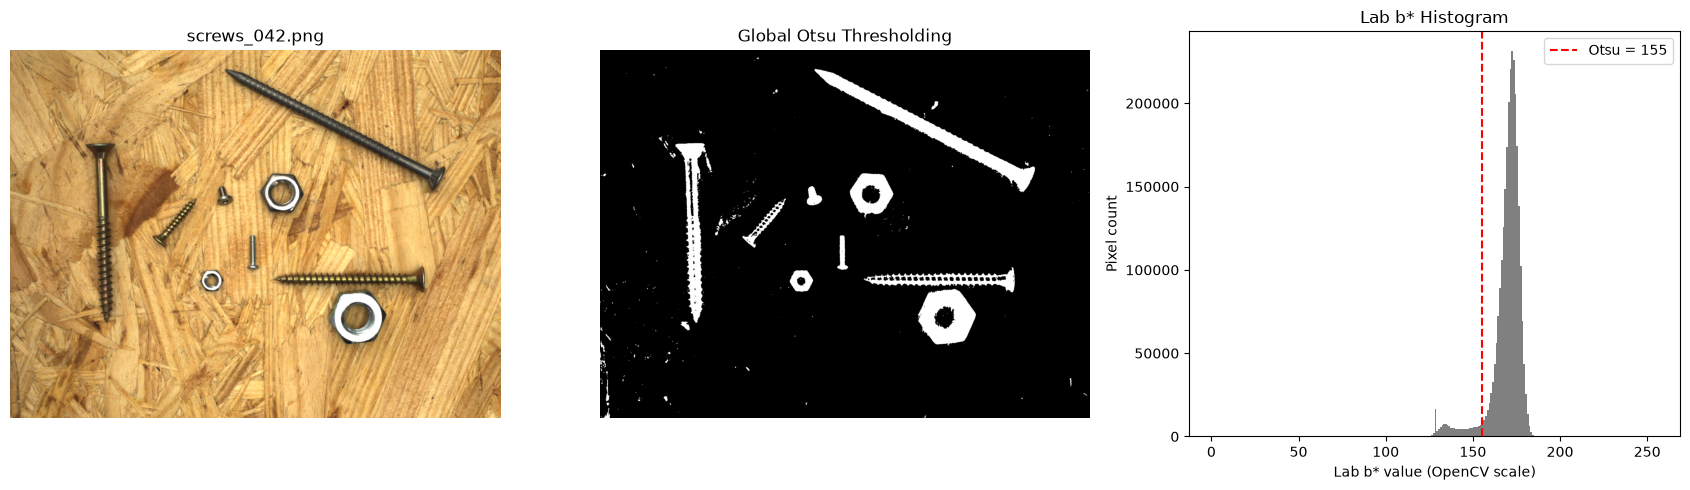

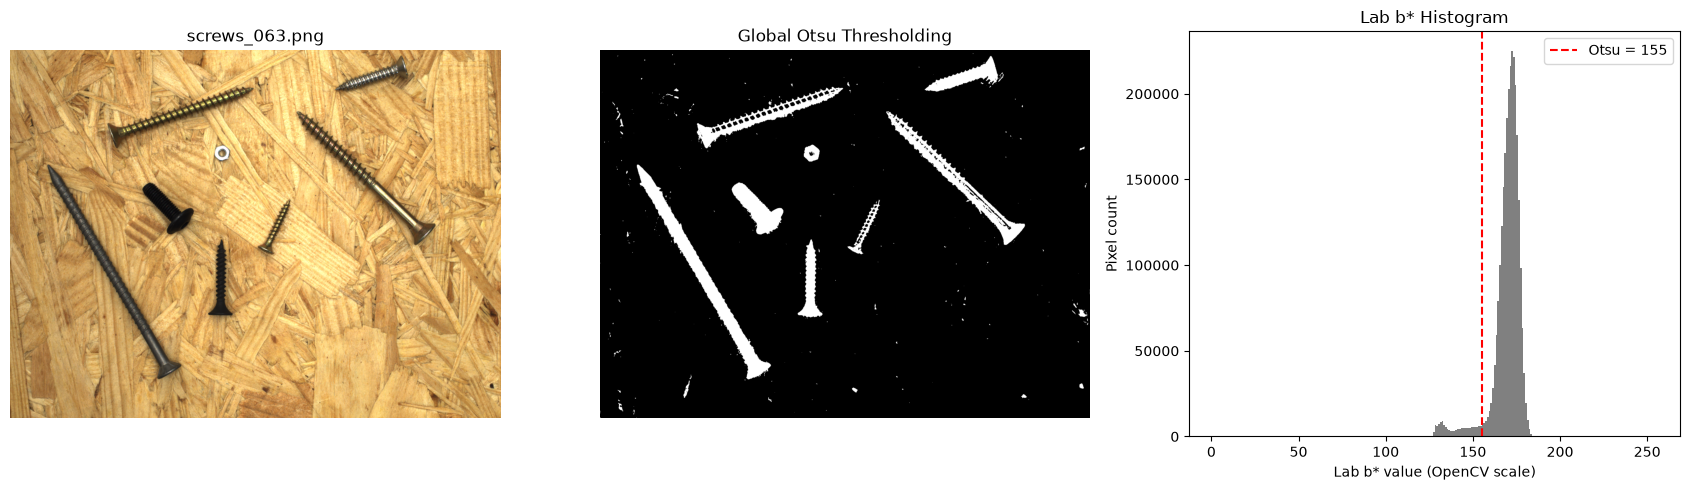

In [25]:
image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

image_paths = sorted(
    path for path in active_paths
    if path.is_file() and path.suffix.lower() in image_extensions
)

# Show every second imagine in the first 10 images (annotated)
for image_path in image_paths[2:10:2]:

    image = cv2.imread(str(image_path))

    if image is None:
        continue

    # Global threshold segmentation
    mask = segment_global_threshold(image)

    # Extract Lab b* channel
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    b_channel = lab[:, :, 2]

    # Apply same Gaussian blur as segmentation function
    blurred = cv2.GaussianBlur(b_channel, (5, 5), 0)

    # Calculate Otsu threshold
    threshold, _ = cv2.threshold(
        blurred,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    # Plot original image, segmentation and histogram
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))

    axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    axes[0].set_title(image_path.name)

    axes[1].imshow(mask, cmap="gray")
    axes[1].set_title("Global Otsu Thresholding")

    axes[2].hist(
        blurred.ravel(),
        bins=256,
        range=(0, 256),
        color="gray"
    )

    axes[2].axvline(
        threshold,
        color="red",
        linestyle="--",
        label=f"Otsu = {threshold:.0f}"
    )

    axes[2].set_title("Lab b* Histogram")
    axes[2].set_xlabel("Lab b* value (OpenCV scale)")
    axes[2].set_ylabel("Pixel count")
    axes[2].legend()

    for ax in axes[:2]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [37]:
global_results = []

for image_path in image_paths:

    gt_path = ANNOTATIONS_DIR / f"{image_path.stem}_labels.png"

    if not gt_path.exists():
        continue

    image = cv2.imread(str(image_path))
    gt_labels = cv2.imread(str(gt_path), cv2.IMREAD_UNCHANGED)

    if image is None or gt_labels is None:
        continue

    # Predicted and ground-truth foreground masks
    pred_mask = segment_global_threshold(image) > 0
    gt_mask = gt_labels > 0

    # Calculate foreground IoU
    intersection = np.logical_and(pred_mask, gt_mask).sum()
    union = np.logical_or(pred_mask, gt_mask).sum()

    iou = intersection / union if union > 0 else 1.0

    global_results.append({
        "Image": image_path.name,
        "IoU": iou
    })

global_results_df = pd.DataFrame(global_results)

display(global_results_df.round(3))

print(
    "Global Otsu Mean IoU:",
    round(global_results_df["IoU"].mean(), 3)
)

,Image,IoU
0,screws_026.png,0.826
1,screws_027.png,0.864
2,screws_028.png,0.872
3,screws_029.png,0.845
4,screws_040.png,0.879
5,screws_041.png,0.768
6,screws_042.png,0.780
7,screws_061.png,0.751
8,screws_063.png,0.772
9,screws_119.png,0.834


Global Otsu Mean IoU: 0.819


Global Otsu thresholding performs reasonably well considering its simplicity, successfully detecting most of the screws and nuts across the images. The majority of the wooden background is removed, and the objects are generally recognisable in the resulting binary masks. However, background noise is still present particularly in small regions of wood incorrectly classified as foreground.

The method appears to perform better on the first two images, which have brighter illumination and a different apparent white balance compared with later images. Their Lab b* histograms show relatively clear peaks around 130 and 175, suggesting that the metal parts and wooden background have more distinguishable colour distributions. This allows Otsu to identify a threshold that separates much of the foreground from the background.

In contrast, later images show less clearly separated histogram peaks. For example, the histogram of screws_63 is not clearly bimodal, with a gradual change in pixel frequency between the main peaks rather than a distinct minimum. 

Although most parts are still detected, the resulting masks contain more false-positive regions from the wooden background. In some cases, these regions are connected to the metal parts, producing larger or irregular foreground components. This is particularly problematic for counting, as connected background regions may distort the detected object boundaries or join separate regions together.

Some nut holes are also incorrectly classified as foreground. This reduces segmentation accuracy because the holes should remain part of the background. 

These results highlight the main limitation of global thresholding. Although Otsu automatically selects a threshold for each image, it applies the exact same threshold to every pixel within that image. This becomes problematic when illumination varies locally or when different metal finishes have overlapping colour distributions with the wooden background. There is also the issue of specular highlights from reflections on shiny surfaces. Relying strictly on global thresholding causes shadow regions to be misclassified as metal, and highlighted metal to blend into the wood. While considerable morphological post-processing could fix these errors on a case-by-case basis, such an approach is brittle and will not generalise well across a wide range of illuminations or varying shadow positions.

# 2. Local Thresholding

Local adaptive thresholding attempts to address the above limitations by calculating a different threshold for each pixel based on its surrounding neighbourhood. This allows the threshold to respond to local variations in the image rather than relying on a single global value.

For consistency with the first method, the Lab b* channel is used again, with the same Gaussian blur applied for pre-processing. Gaussian adaptive thresholding is selected because it calculates the local threshold using a weighted average of neighbouring pixels, giving greater importance to nearby pixels.

Two parameters must be selected:

Window size (blockSize): Determines the neighbourhood used to calculate each threshold. Smaller windows respond more strongly to local changes but may be sensitive to wood texture and noise. Larger windows produce smoother thresholds but may be less effective at handling local variations.

Offset (C): Adjusts the calculated threshold. With inverse binary thresholding, increasing C lowers the threshold and generally produces fewer foreground pixels.



In [67]:
def segment_adaptive_threshold(image, block_size, C):

    # Convert to Lab and extract b* channel
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    b_channel = lab[:, :, 2]

    # Same preprocessing as global thresholding
    blurred = cv2.GaussianBlur(b_channel, (5, 5), 0)

    # Adaptive Gaussian threshold
    mask = cv2.adaptiveThreshold(
        blurred,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV,
        block_size,
        C
    )

    return mask


Adaptive Gaussian thresholding requires two parameters: the neighbourhood size (N) and the offset (C). To determine suitable values, an iterative parameter investigation was carried out using foreground Intersection over Union (IoU) against the annotated masks.

The investigation began with small neighbourhood sizes (11, 31 and 51 pixels) and offsets (0, 3 and 5). These produced low IoU scores, with the best-performing combinations consistently occurring at the largest neighbourhood size and offset within each tested range.

This suggested that the initial parameter ranges were insufficient to capture the complete metal objects. Therefore, both N and C were progressively increased, with the search range extended whenever the highest IoU occurred at its upper boundary.

The aim was to identify a region where segmentation performance stabilised and further increases in the parameters provided little additional improvement. This approach allowed the parameters to be selected using quantitative evidence rather than visual inspection alone.

In [82]:
parameter_results = []

block_sizes = [851, 901, 951]
offsets = [15, 18, 21]  

for block_size in block_sizes:
    for C in offsets:

        iou_scores = []

        for image_path in image_paths:

            gt_path = ANNOTATIONS_DIR / f"{image_path.stem}_labels.png"

            if not gt_path.exists():
                continue

            image = cv2.imread(str(image_path))
            gt_labels = cv2.imread(
                str(gt_path),
                cv2.IMREAD_UNCHANGED
            )

            if image is None or gt_labels is None:
                continue

            pred_mask = segment_adaptive_threshold(
                image,
                block_size=block_size,
                C=C
            ) > 0

            gt_mask = gt_labels > 0

            intersection = np.logical_and(pred_mask, gt_mask).sum()
            union = np.logical_or(pred_mask, gt_mask).sum()

            iou = intersection / union if union > 0 else 1.0
            iou_scores.append(iou)

        parameter_results.append({
            "Window": block_size,
            "C": C,
            "Mean IoU": np.mean(iou_scores)
        })

parameter_df = pd.DataFrame(parameter_results)

display(
    parameter_df.sort_values(
        "Mean IoU", ascending=False
    ).round(3)
)

,Window,C,Mean IoU
7,951,18,0.842
4,901,18,0.842
1,851,18,0.842
0,851,15,0.825
8,951,21,0.824
3,901,15,0.824
5,901,21,0.822
6,951,15,0.822
2,851,21,0.819


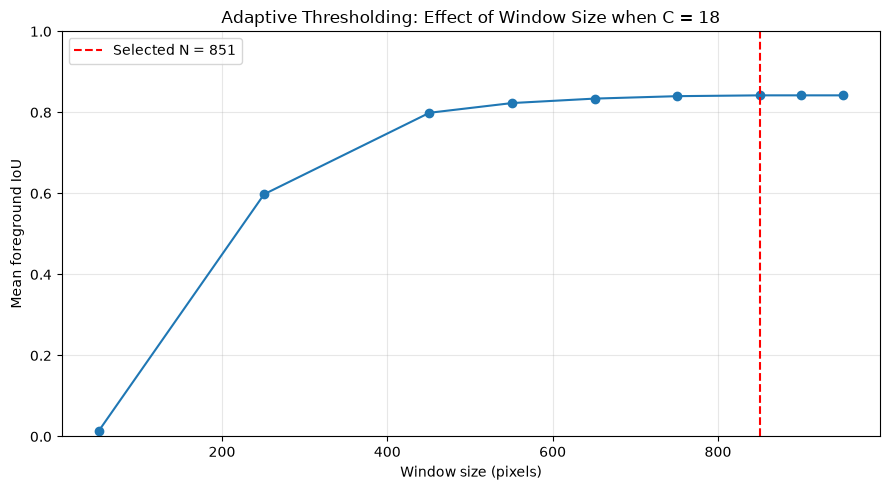

In [84]:
# Measured results with C = 18
window_sizes = [51, 251, 451, 551, 651, 751, 851, 901, 951]
mean_ious = [0.014, 0.598, 0.799, 0.823, 0.834, 0.840, 0.842, 0.842, 0.842]

plt.figure(figsize=(9, 5))

plt.plot(window_sizes, mean_ious, marker="o")

plt.axvline(
    851,
    color="red",
    linestyle="--",
    label="Selected N = 851"
)

plt.xlabel("Window size (pixels)")
plt.ylabel("Mean foreground IoU")
plt.title("Adaptive Thresholding: Effect of Window Size when C = 18")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

The iterative investigation showed that small neighbourhoods detected only parts of the metal objects, resulting in low IoU. Increasing the neighbourhood size and offset almost always improved segmentation performance.

The final parameter comparison considered neighbourhood sizes of 851, 901 and 951 pixels and offsets of 15, 18 and 21.

Unlike the earlier experiments, the best result was no longer obtained using the largest values of both parameters. Instead, an offset of C = 18 achieved the highest mean IoU of approximately 0.842 across all three neighbourhood sizes. Increasing C to 21 reduced performance. Increasing the neighbourhood size beyond 851 also produced no measurable improvement at three decimal places, suggesting that the performance had reached a plateau within the tested range.

Therefore, N = 851 and C = 18 were selected as the smallest tested neighbourhood achieving the highest reported mean IoU.

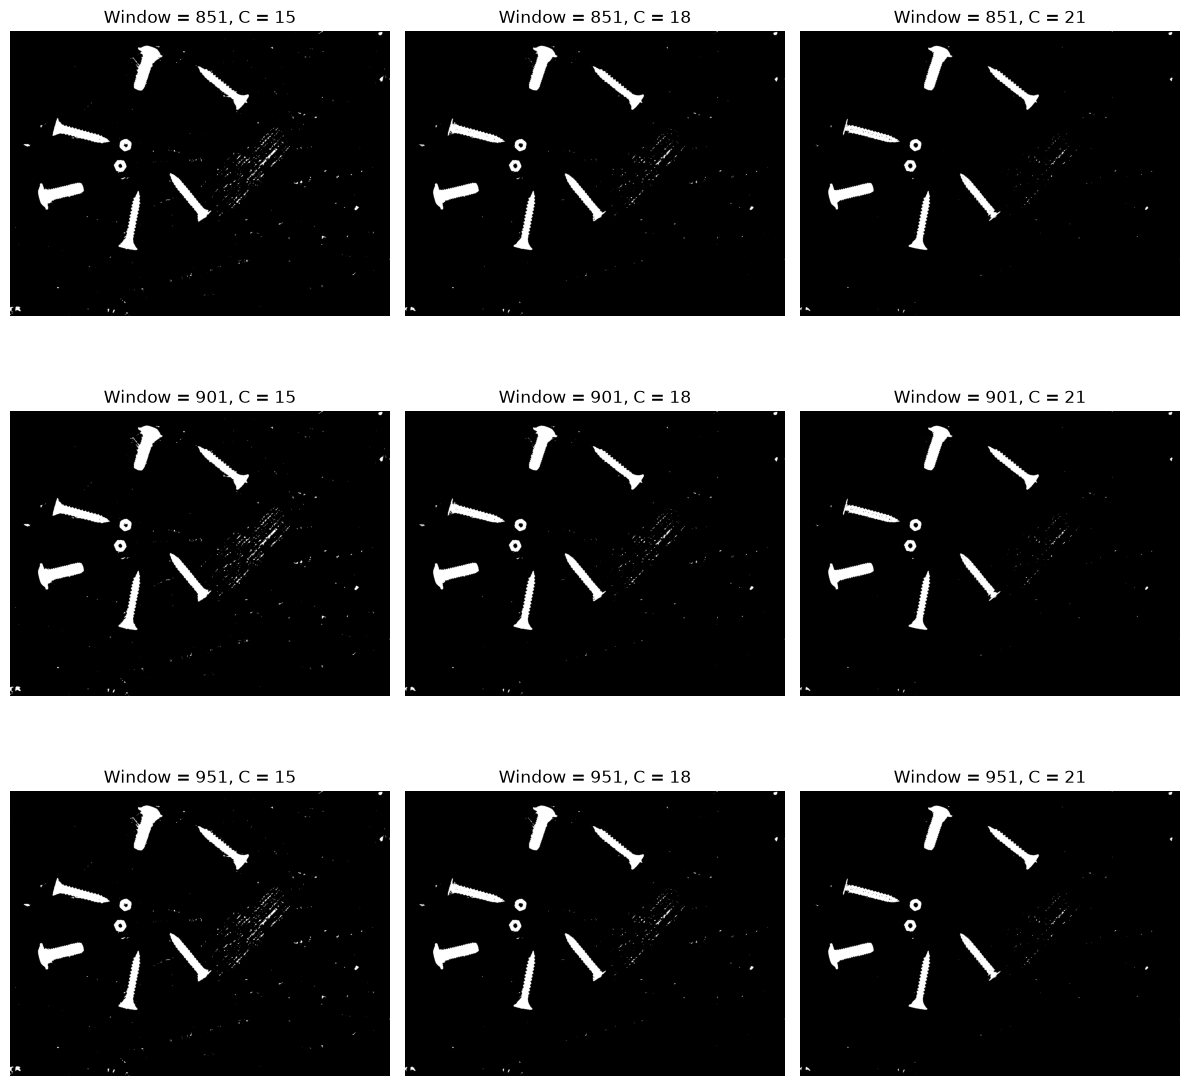

In [83]:
block_sizes = [851, 901, 951]
offsets = [15, 18, 21]  

image = cv2.imread(str(image_paths[0]))

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for i, block_size in enumerate(block_sizes):
    for j, C in enumerate(offsets):

        mask = segment_adaptive_threshold(
            image,
            block_size=block_size,
            C=C
        )

        axes[i, j].imshow(mask, cmap="gray")
        axes[i, j].set_title(f"Window = {block_size}, C = {C}")
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

Visual inspection shows an improvement when increasing the offset from C = 15 to C = 18 at N = 851. In particular, some unwanted foreground regions surrounding the upper-middle and upper-left screws are reduced, allowing their shapes to be preserved more accurately.

At C = 15, some of these regions appear connected to the detected screws, distorting their boundaries. Increasing the offset to C = 18 reduces these unwanted connections, producing cleaner objects. This is important for connected-component labelling, as foreground noise attached to an object can affect its shape and potentially cause neighbouring parts to merge.

Although the selected parameters achieved a mean foreground IoU of approximately 0.842, the binary masks still contain some holes and irregular regions. 

The method will therefore be evaluated alongside the other segmentation approaches using identical post-processing, with the final comparison considering both pixel-level segmentation quality and part-counting performance.
